In [1]:
!pip install openpyxl

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [3]:
dados = pd.read_excel('/content/Online Retail.xlsx')

print(dados.shape)

dados.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print(dados.columns.tolist())
print(dados.dtypes)
print(dados.isnull().sum())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
dados['InvoiceDate'] = pd.to_datetime(dados['InvoiceDate'])

print(dados['InvoiceDate'].min())
print(dados['InvoiceDate'].max())

print(dados['CustomerID'].nunique())

print(dados['InvoiceNo'].nunique())

print(dados['InvoiceNo'].astype(str).str.startswith('C').sum())

print(round(dados['CustomerID'].isna().mean() * 100, 2), "%")

2010-12-01 08:26:00
2011-12-09 12:50:00
4372
25900
9288
24.93 %


In [7]:
dados = dados.dropna(subset=['CustomerID']).copy()

dados['CustomerID'] = dados['CustomerID'].astype(int)

dados['InvoiceNo'] = dados['InvoiceNo'].astype(str)

dados['is_cancelled'] = dados['InvoiceNo'].str.startswith('C')

dados['total_value'] = dados['Quantity'] * dados['UnitPrice']

print(len(dados))
print(dados['CustomerID'].nunique())
print(dados['is_cancelled'].sum())
print(round(dados['total_value'].sum(), 2))

406829
4372
8905
8300065.81


In [8]:
dados_validos = dados[
    (~dados['is_cancelled']) &
    (dados['Quantity'] > 0) &
    (dados['UnitPrice'] > 0)
].copy()

dados_validos['InvoiceDate'] = pd.to_datetime(
    dados_validos['InvoiceDate']
)

print(dados_validos.shape[0])
print(dados_validos['CustomerID'].nunique())
print(dados_validos['InvoiceDate'].min())
print(dados_validos['InvoiceDate'].max())

397884
4338
2010-12-01 08:26:00
2011-12-09 12:50:00


In [9]:
data_corte = pd.Timestamp('2011-10-31 23:59:59')
inicio_target = pd.Timestamp('2011-11-01')
fim_target = pd.Timestamp('2011-11-30 23:59:59')

dados_observacao = dados_validos[
    dados_validos['InvoiceDate'] <= data_corte
].copy()

dados_target = dados_validos[
    (dados_validos['InvoiceDate'] >= inicio_target) &
    (dados_validos['InvoiceDate'] <= fim_target)
].copy()

features_clientes = dados_observacao.groupby('CustomerID').agg(
    recency_days=('InvoiceDate', lambda x: (data_corte - x.max()).days),
    frequency=('InvoiceNo', 'nunique'),
    monetary_value=('total_value', 'sum')
).reset_index()

clientes_recompra = dados_target['CustomerID'].unique()

features_clientes['repurchased'] = (
    features_clientes['CustomerID'].isin(clientes_recompra).astype(int)
)

print(features_clientes.shape[0])
print("\nDistribuição do target:")
print(features_clientes['repurchased'].value_counts())
print("\nBase final:")
display(features_clientes.head())

3974

Distribuição do target:
repurchased
0    2633
1    1341
Name: count, dtype: int64

Base final:


,CustomerID,recency_days,frequency,monetary_value,repurchased
0,12346,286,1,77183.60,0
1,12347,0,6,4085.18,0
2,12348,36,4,1797.24,0
3,12350,271,1,334.40,0
4,12352,33,7,2194.31,1


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

X = features_clientes[
    ['recency_days', 'frequency', 'monetary_value']
]

y = features_clientes['repurchased']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

modelo = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

modelo.fit(X_train, y_train)

previsoes = modelo.predict(X_test)

print(round(accuracy_score(y_test, previsoes), 4))

print(classification_report(y_test, previsoes, zero_division=0))

print(confusion_matrix(y_test, previsoes))

0.7157
              precision    recall  f1-score   support

           0       0.74      0.88      0.80       527
           1       0.62      0.40      0.48       268

    accuracy                           0.72       795
   macro avg       0.68      0.64      0.64       795
weighted avg       0.70      0.72      0.70       795

[[463  64]
 [162 106]]


In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

previsoes_baseline = baseline.predict(X_test)

print(round(accuracy_score(y_test, previsoes_baseline), 4))

print(classification_report(
    y_test,
    previsoes_baseline,
    zero_division=0
))

0.6629
              precision    recall  f1-score   support

           0       0.66      1.00      0.80       527
           1       0.00      0.00      0.00       268

    accuracy                           0.66       795
   macro avg       0.33      0.50      0.40       795
weighted avg       0.44      0.66      0.53       795



In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

modelos = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight="balanced",
        random_state=42
    )
}

for nome, modelo_teste in modelos.items():
    modelo_teste.fit(X_train, y_train)
    previsoes_teste = modelo_teste.predict(X_test)

    print(f"\n{'='*40}")
    print(nome)
    print(round(accuracy_score(y_test, previsoes_teste), 4))
    print(classification_report(y_test, previsoes_teste, zero_division=0))
    print(confusion_matrix(y_test, previsoes_teste))


Decision Tree
0.6465
              precision    recall  f1-score   support

           0       0.77      0.66      0.71       527
           1       0.48      0.62      0.54       268

    accuracy                           0.65       795
   macro avg       0.63      0.64      0.63       795
weighted avg       0.68      0.65      0.65       795

[[347 180]
 [101 167]]

Random Forest
0.6855
              precision    recall  f1-score   support

           0       0.77      0.75      0.76       527
           1       0.53      0.56      0.55       268

    accuracy                           0.69       795
   macro avg       0.65      0.65      0.65       795
weighted avg       0.69      0.69      0.69       795

[[395 132]
 [118 150]]


In [13]:
resultados = []

for nome, modelo_teste in modelos.items():
    previsoes_teste = modelo_teste.predict(X_test)

    resultados.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_test, previsoes_teste),
        'Precisão': classification_report(
            y_test, previsoes_teste, output_dict=True, zero_division=0
        )['1']['precision'],
        'Recall': classification_report(
            y_test, previsoes_teste, output_dict=True, zero_division=0
        )['1']['recall'],
        'F1-score': classification_report(
            y_test, previsoes_teste, output_dict=True, zero_division=0
        )['1']['f1-score']
    })

resultados.append({
    'Modelo': 'Baseline',
    'Acurácia': accuracy_score(y_test, previsoes_baseline),
    'Precisão': 0,
    'Recall': 0,
    'F1-score': 0
})

comparacao = pd.DataFrame(resultados)

display(comparacao.round(3))

,Modelo,Acurácia,Precisão,Recall,F1-score
0,Decision Tree,0.647,0.481,0.623,0.543
1,Random Forest,0.686,0.532,0.560,0.545
2,Baseline,0.663,0.000,0.000,0.000


ROC-AUC: 0.7172


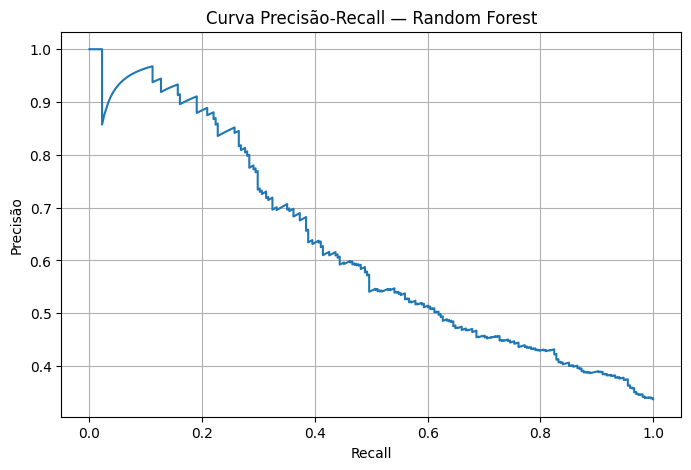

In [14]:
from sklearn.metrics import roc_auc_score, precision_recall_curve
import matplotlib.pyplot as plt

modelo_final = modelos['Random Forest']

probabilidades = modelo_final.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, probabilidades)

print("ROC-AUC:", round(auc, 4))

precisions, recalls, thresholds = precision_recall_curve(
    y_test, probabilidades
)

plt.figure(figsize=(8, 5))
plt.plot(recalls, precisions)
plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title("Curva Precisão-Recall — Random Forest")
plt.grid(True)
plt.show()

,Feature,Importance
2,monetary_value,0.426147
0,recency_days,0.340957
1,frequency,0.232896


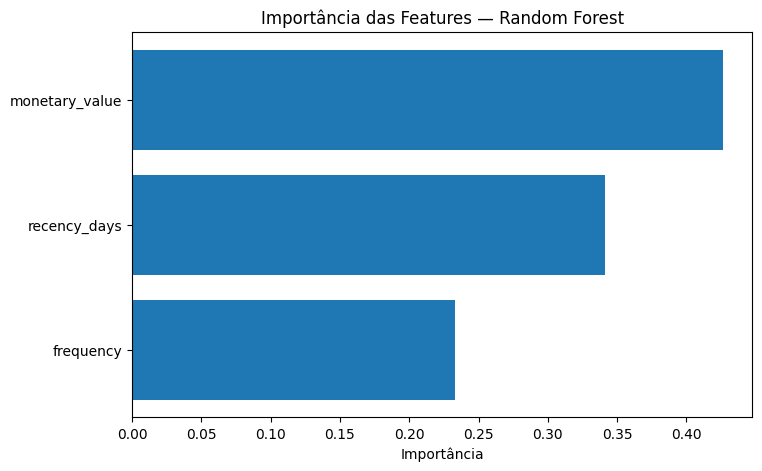

In [15]:
importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': modelo_final.feature_importances_
}).sort_values(by='Importance', ascending=False)

display(importances)

plt.figure(figsize=(8, 5))
plt.barh(importances['Feature'], importances['Importance'])
plt.xlabel('Importância')
plt.title('Importância das Features — Random Forest')
plt.gca().invert_yaxis()
plt.show()

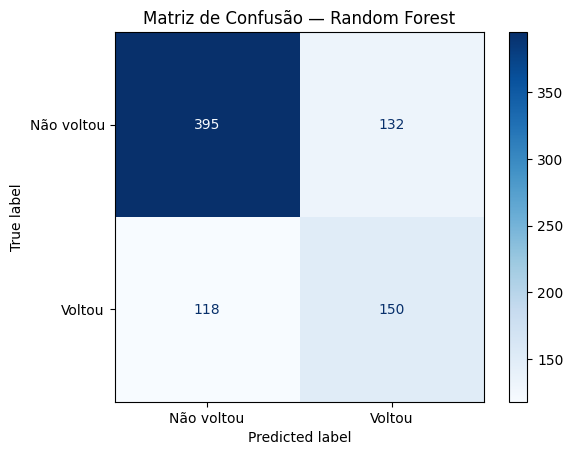

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

previsoes_finais = modelo_final.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    previsoes_finais,
    display_labels=['Não voltou', 'Voltou'],
    cmap='Blues'
)

plt.title('Matriz de Confusão — Random Forest')
plt.show()

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

metricas_finais = pd.DataFrame({
    'Métrica': [
        'Acurácia',
        'Precisão',
        'Recall',
        'F1-score',
        'ROC-AUC'
    ],
    'Resultado': [
        accuracy_score(y_test, previsoes_finais),
        precision_score(y_test, previsoes_finais, zero_division=0),
        recall_score(y_test, previsoes_finais, zero_division=0),
        f1_score(y_test, previsoes_finais, zero_division=0),
        roc_auc_score(y_test, modelo_final.predict_proba(X_test)[:, 1])
    ]
})

metricas_finais['Resultado'] = metricas_finais['Resultado'].round(4)

display(metricas_finais)

,Métrica,Resultado
0,Acurácia,0.6855
1,Precisão,0.5319
2,Recall,0.5597
3,F1-score,0.5455
4,ROC-AUC,0.7172


In [18]:
import joblib

joblib.dump(modelo_final, 'customer_repurchase_model.pkl')

features_clientes.to_csv(
    'customer_repurchase_dataset.csv',
    index=False
)

comparacao.to_csv(
    'model_comparison.csv',
    index=False
)

metricas_finais.to_csv(
    'final_metrics.csv',
    index=False
)

print("Arquivos exportados com sucesso!")

Arquivos exportados com sucesso!


In [19]:
from google.colab import files

files.download('customer_repurchase_model.pkl')
files.download('customer_repurchase_dataset.csv')
files.download('model_comparison.csv')
files.download('final_metrics.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>